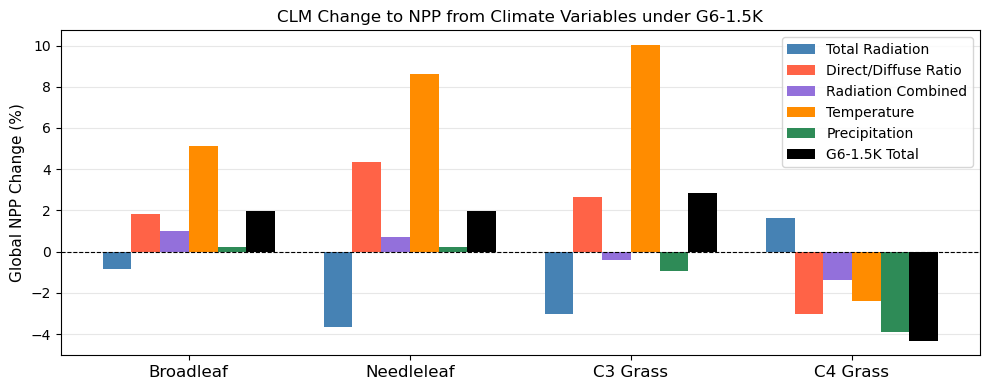

In [2]:
import pyreadr
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import xarray as xr
import numpy as np
import pandas as pd
from scipy.special import expit 
import os

raddir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_rad'
precipdir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_precip'
tempdir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_temperature'
totaldir = '/glade/derecho/scratch/brendanc/make_pft/CLM/'

case1 = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_case1_2050-2069.clm2.h1.NPP.nc")
case1 = case1["__xarray_dataarray_variable__"]
case2 = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_case2_2050-2069.clm2.h1.NPP.nc")
case2 = case2["__xarray_dataarray_variable__"] 
ssp = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.SSP245_006_2050-2069.clm2.h1.NPP.nc")
ssp = ssp["__xarray_dataarray_variable__"] 
precip = xr.open_dataset(precipdir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_precip_2050-2069.clm2.h1.NPP.nc")
precip = precip["__xarray_dataarray_variable__"] 
temp = xr.open_dataset(tempdir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_temperature_2050-2069_final.clm2.h1.NPP.nc")
temp = temp["__xarray_dataarray_variable__"]
total_G6 = xr.open_dataset(totaldir + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h1.NPP.latlon.coupled_nonan.205001-206912.nc")
total_G6 = total_G6["__xarray_dataarray_variable__"]
total_SSP = xr.open_dataset(totaldir + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h1.NPP.latlon_nonan.201501-206912.nc")
total_SSP = total_SSP["__xarray_dataarray_variable__"]

case1 = case1.sel(time=slice('2050-01-01', '2069-12-31'))
case2 = case2.sel(time=slice('2050-01-01', '2069-12-31'))
ssp = ssp.sel(time=slice('2050-01-01', '2069-12-31'))
precip = precip.sel(time=slice('2050-01-01', '2069-12-31'))
temp = temp.sel(time=slice('2050-01-01', '2069-12-31'))
total_G6  = total_G6.sel(time=slice('2050-01-01', '2069-12-31'))
total_SSP = total_SSP.sel(time=slice('2050-01-01', '2069-12-31'))

case1_annual = case1.resample(time='YE').mean(skipna=True)
case2_annual = case2.resample(time='YE').mean(skipna=True)
ssp_annual   = ssp.resample(time='YE').mean(skipna=True)
precip_annual = precip.resample(time='YE').mean(skipna=True)
temp_annual   = temp.resample(time='YE').mean(skipna=True)
total_G6_annual  = total_G6.resample(time='YE').mean(skipna=True)
total_SSP_annual = total_SSP.resample(time='YE').mean(skipna=True)

pft_names = {
    0:  'Bare Ground',
    1:  'Needleleaf evergreen tree – temperate',
    2:  'Needleleaf evergreen tree – boreal',
    3:  'Needleleaf deciduous tree – boreal',
    4:  'Broadleaf evergreen tree – tropical',
    5:  'Broadleaf evergreen tree – temperate',
    6:  'Broadleaf deciduous tree – tropical',
    7:  'Broadleaf deciduous tree – temperate',
    8:  'Broadleaf deciduous tree – boreal',
    9:  'Broadleaf evergreen shrub – temperate',
    10: 'Broadleaf deciduous shrub – temperate',
    11: 'Broadleaf deciduous shrub – boreal',
    12: 'C3 arctic grass',
    13: 'C3 grass',
    14: 'C4 grass',
}

def assign_pft_names(da):
    pft_indices = da.pft.values
    names = [pft_names.get(int(i), f'PFT {int(i)}') for i in pft_indices]
    return da.assign_coords(pft_name=('pft', names))

case1_annual = assign_pft_names(case1_annual)
case2_annual = assign_pft_names(case2_annual)
ssp_annual   = assign_pft_names(ssp_annual)
precip_annual = assign_pft_names(precip_annual)
temp_annual   = assign_pft_names(temp_annual)
total_G6_annual  = assign_pft_names(total_G6_annual)
total_SSP_annual = assign_pft_names(total_SSP_annual)

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import textwrap

ssp_tavg    = ssp_annual.mean(dim='time')
case1_tavg  = case1_annual.mean(dim='time')
case2_tavg  = case2_annual.mean(dim='time')
temp_tavg   = temp_annual.mean(dim='time')
precip_tavg = precip_annual.mean(dim='time')
total_G6_tavg  = total_G6_annual.mean(dim='time')
total_SSP_tavg = total_SSP_annual.mean(dim='time')

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

broad_pfts = [4, 5, 6, 7, 8]
ever_pfts  = [1]
c3_pfts    = [13]
c4_pfts    = [14]

lat_weights = np.cos(np.deg2rad(ssp_tavg.lat))
lat_weights = lat_weights / lat_weights.sum()

def area_weighted_mean(da):
    return float(da.weighted(lat_weights).mean(('lat', 'lon'), skipna=True))

def select_pfts(da, pft_list):
    return da.sel(pft=pft_list).sum('pft')

def pct_diff(a, b):
    return (a - b) / b * 100

def compute_group(pft_list):
    ssp_g       = select_pfts(ssp_tavg, pft_list)
    case1_g     = select_pfts(case1_tavg, pft_list)
    case2_g     = select_pfts(case2_tavg, pft_list)
    temp_g      = select_pfts(temp_tavg, pft_list)
    precip_g    = select_pfts(precip_tavg, pft_list)
    total_G6_g  = select_pfts(total_G6_tavg, pft_list)
    total_SSP_g = select_pfts(total_SSP_tavg, pft_list)

    ssp_m       = area_weighted_mean(ssp_g)
    case1_m     = area_weighted_mean(case1_g)
    case2_m     = area_weighted_mean(case2_g)
    temp_m      = area_weighted_mean(temp_g)
    precip_m    = area_weighted_mean(precip_g)
    total_G6_m  = area_weighted_mean(total_G6_g)
    total_SSP_m = area_weighted_mean(total_SSP_g)

    tot_rad  = pct_diff(case1_m, ssp_m)
    dirdif   = pct_diff(case2_m, case1_m)
    temp_d   = pct_diff(temp_m, ssp_m)
    precip_d = pct_diff(precip_m, ssp_m)
    total_d  = pct_diff(total_G6_m, total_SSP_m)   # G6 minus SSP, new files

    return tot_rad, dirdif, temp_d, precip_d, total_d

groups = {
    'Broadleaf':  compute_group(broad_pfts),
    'Needleleaf': compute_group(ever_pfts),
    'C3 Grass':   compute_group(c3_pfts),
    'C4 Grass':   compute_group(c4_pfts),
}

labels      = list(groups.keys())
tot_vals    = [groups[k][0] for k in labels]
dif_vals    = [groups[k][1] for k in labels]
temp_vals   = [groups[k][2] for k in labels]
precip_vals = [groups[k][3] for k in labels]
total_vals  = [groups[k][4] for k in labels]
com_vals    = [t + d for t, d in zip(tot_vals, dif_vals)]

x     = np.arange(len(labels))
width = 0.13

fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(axis='y', alpha=0.3, zorder=0)

bars1 = ax.bar(x - 2.5*width, tot_vals,    width, label='Total Radiation',      color='steelblue',    zorder=2)
bars2 = ax.bar(x - 1.5*width, dif_vals,    width, label='Direct/Diffuse Ratio', color='tomato',       zorder=2)
bars3 = ax.bar(x - 0.5*width, com_vals,    width, label='Radiation Combined',   color='mediumpurple', zorder=2)
bars4 = ax.bar(x + 0.5*width, temp_vals,   width, label='Temperature',          color='darkorange',   zorder=2)
bars5 = ax.bar(x + 1.5*width, precip_vals, width, label='Precipitation',        color='seagreen',     zorder=2)
bars6 = ax.bar(x + 2.5*width, total_vals,  width, label='G6-1.5K Total',        color='black',        zorder=2)

ax.axhline(0, color='k', linewidth=0.8, linestyle='--', zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel('Global NPP Change (%)', fontsize=11)
ax.set_title('CLM Change to NPP from Climate Variables under G6-1.5K', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
plt.savefig(f"{savedir}/CLM_bars_total.png", dpi=600, bbox_inches="tight")

In [3]:
print("G6-1.5K Total NPP change (%):")
for label, val in zip(labels, total_vals):
    print(f"  {label:<12}: {val:.2f}%")

G6-1.5K Total NPP change (%):
  Broadleaf   : 1.96%
  Needleleaf  : 1.98%
  C3 Grass    : 2.82%
  C4 Grass    : -4.31%
